# Problem 2.44 (Quadratic Air Drag): 

To get an accurate trajectory for a projectile one must often
take account of several complications. For example, if a projectile goes very high then we have to
allow for the reduction in air resistance as atmospheric density decreases. To illustrate this, consider
an iron cannonball (diameter $15 cm$, density $7.8 g/cm^3$) that is fired with initial velocity $300 m/s$ at 50 degrees above the horizontal. The drag force is approximately quadratic, but since the drag is
proportional to the atmospheric density and the density falls off exponentially with height, the drag
force is $f = c(y)v^2$ where $c(y) = \gamma D^2\exp(−y/\lambda)$ with $\gamma = 0.25 N s^2/m^4$ and $\lambda = 10,000 m.$

(A) Write down the equations of motion for the cannonball and use appropriate software to solve
numerically for $x(t)$ and $y(t)$ for $0 < t < 3.5 s$. Plot the ball's trajectory and find its horizontal range.

(B) Do the same calculation ignoring the variation of atmospheric density (that is, setting $c(y) =
c(0)$), and yet again ignoring air resistance entirely. Plot all three trajectories for $0 < t < 3.5 s$ on the same graph. You will find that in this case air resistance makes a huge difference and that the
variation of air resistance makes a small, but not negligible, difference.

**A.** By Newton's 2nd Law we have is

$$
\vec{F} = m\vec{a} \Longrightarrow m\vec{g} - c(y)v^2\hat{v} = m\vec{a} \\
\dot{\vec{v}} = -g\hat{y} - \frac{\gamma}{m}D^2e^{-y/\lambda}v^2\hat{v} 
\quad \\
\dot{\vec{v}} = -g\hat{y} - \frac{\gamma}{m}D^2e^{-y/\lambda}v\vec{v}
$$

These can be broken down into $x$ and $y$ components to get the equation of motion in each direction:

$$
\dot{v}_x = -\frac{\gamma}{m}D^2e^{-y/\lambda}\sqrt{v_x^2 + v_y^2}v_x \\
\dot{v}_y = -g -\frac{\gamma}{m}D^2e^{-y/\lambda}\sqrt{v_x^2 + v_y^2}v_y
$$

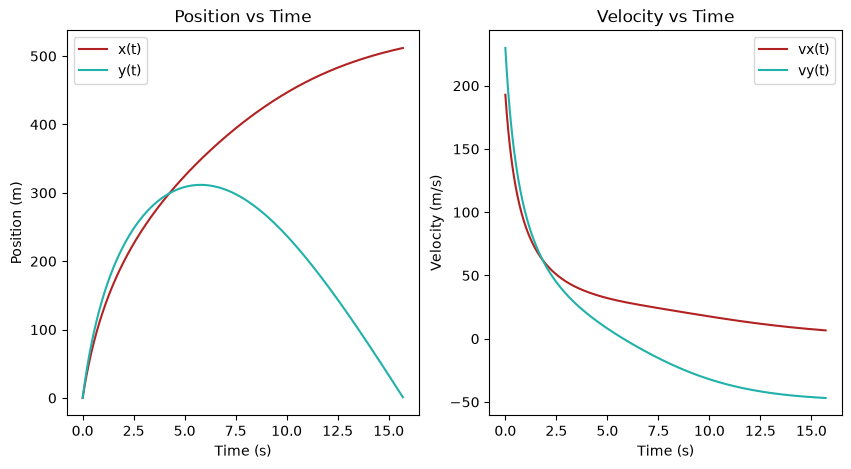

Range = 511.82 m


In [47]:
import numpy as np 
import scipy as sp
import matplotlib.pyplot as plt

# Constants
g = 9.81
theta = 50 * np.pi / 180
v0 = 300
D = 15e-3
rho = 7.89e3
gamma = 0.25
lam = 10000

m = rho * (4/3) * np.pi * (D/2)**3

# Equations of motion
def c_func(y):
    return gamma * D**2 * np.exp(-y/lam)

def projectile_motion(c, t_max=35):


    def vx_p(y, vx, vy):
        v = np.sqrt(vx**2 + vy**2)
        return -c(y)/m * v * vx

    def vy_p(y, vx, vy):
        v = np.sqrt(vx**2 + vy**2)
        return -g - c(y)/m * v * vy

    # State vector
    def state(t, z):
        x, y, vx, vy = z
        return np.array([
            vx,
            vy,
            vx_p(y, vx, vy),
            vy_p(y, vx, vy)
        ])

    # Time span
    t_span = (0, t_max)
    t_eval = np.linspace(t_span[0], t_span[1], 1000)

    def hit_ground(t, z):
        return z[1]

    hit_ground.terminal = True
    hit_ground.direction = -1

    # Initial conditionns
    z0 = [0, 0, v0 * np.cos(theta), v0 * np.sin(theta)]

    sol = sp.integrate.solve_ivp(
        state,
        t_span,
        z0,
        t_eval=t_eval,
        events=hit_ground
    )

    t = sol.t
    x = sol.y[0]
    y = sol.y[1]
    vx = sol.y[2]
    vy = sol.y[3]

    colors = ['firebrick', 'lightseagreen']

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.plot(t, x, label='x(t)', color=colors[0])
    plt.plot(t, y, label='y(t)', color=colors[1])
    plt.xlabel('Time (s)')
    plt.ylabel('Position (m)')
    plt.title('Position vs Time')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(t, vx, label='vx(t)', color=colors[0])
    plt.plot(t, vy, label='vy(t)', color=colors[1])
    plt.xlabel('Time (s)')
    plt.ylabel('Velocity (m/s)')
    plt.title('Velocity vs Time')
    plt.legend()

    plt.show()

    print(f"Range = {x[-1]:.2f} m")

projectile_motion(c_func)

**B.** Lets suppose we don't account for the variation in air density, so $c(y) = c(0)$. Then

$$
c(y) = c(0) = \gamma D^2e^0 = \gamma D^2
$$

And we expect the projectile to not go quite as far, since the exponential factor made the drag force less significant. 

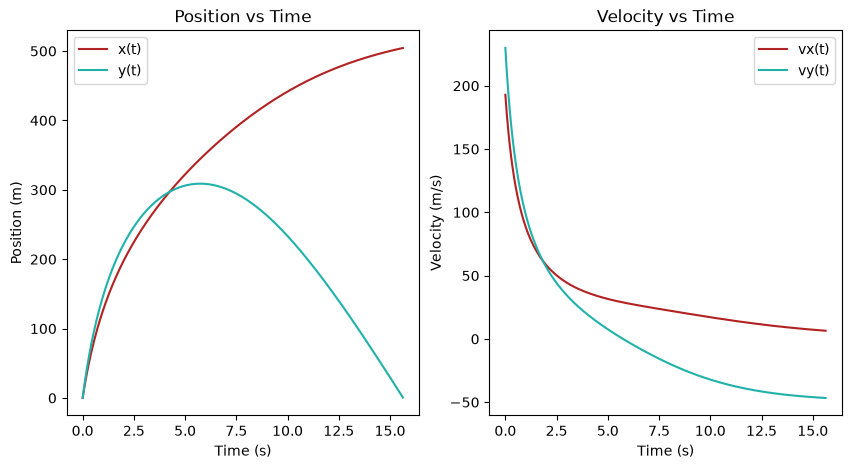

Range = 504.36 m


In [43]:
projectile_motion(lambda y: gamma * D**2)

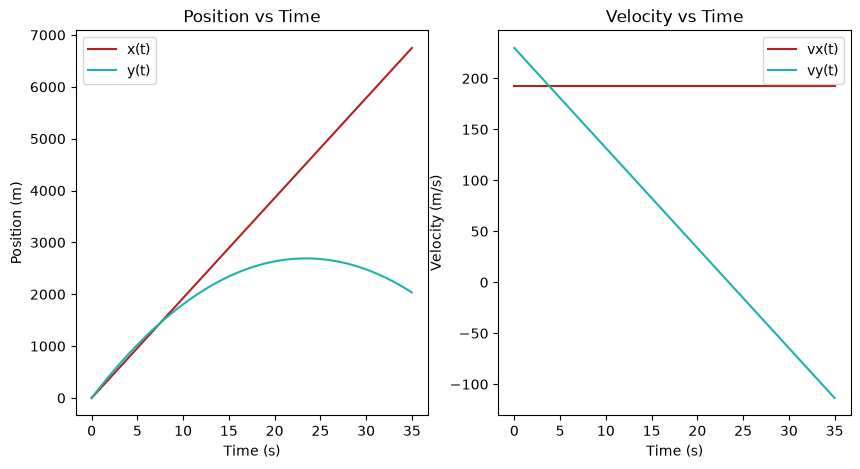

Range = 6749.27 m


In [45]:
projectile_motion(lambda y: 0)